In [ ]:
from huggingface_hub import hf_hub_download, notebook_login
notebook_login()

# Libraries

In [ ]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
if IN_COLAB:
    %pip install "torch>=2.1.0" einops datasets jaxtyping "sae_lens>=3.23.1" openai tabulate "nbformat>=4.2.0" umap-learn hdbscan eindex-callum git+https://github.com/callummcdougall/CircuitsVis.git#subdirectory=python git+https://github.com/callummcdougall/sae_vis.git@callum/v3 "transformer-lens>=2.7.0"
from IPython.display import HTML, IFrame, clear_output, display
import random
from rich import print as rprint
from rich.table import Table
from tqdm.auto import tqdm
from functools import partial
import torch as t
import torch.nn.functional as F
from torch import Tensor, nn
from jaxtyping import Float, Int
import einops

import matplotlib.pyplot as plt
import numpy as np

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

from sae_lens.toolkit.pretrained_saes_directory import get_pretrained_saes_directory
from sae_lens import (
    SAE,
    ActivationsStore,
    HookedSAETransformer,
    LanguageModelSAERunnerConfig,
    SAEConfig,
    SAETrainingRunner,
    upload_saes_to_huggingface,
)

from transformer_lens import ActivationCache, HookedTransformer, utils
from transformer_lens.hook_points import HookPoint
from tabulate import tabulate

from google.colab import drive
import pickle, glob

  Cloning https://github.com/callummcdougall/CircuitsVis.git to /tmp/pip-req-build-7jhliie_
  Running command git clone --filter=blob:none --quiet https://github.com/callummcdougall/CircuitsVis.git /tmp/pip-req-build-7jhliie_
  Resolved https://github.com/callummcdougall/CircuitsVis.git to commit 1e6129d08cae7af9242d9ab5d3ed322dd44b4dd3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/callummcdougall/sae_vis.git (to revision callum/v3) to /tmp/pip-req-build-efn55ou1
  Running command git clone --filter=blob:none --quiet https://github.com/callummcdougall/sae_vis.git /tmp/pip-req-build-efn55ou1
  Running command git checkout -b callum/v3 --track origin/callum/v3
  Switched to a new branch 'callum/v3'
  Branch 'callum/v3' set up to track remote branch 'callum/v3' from 'origin'.
  Resolved https://github.com/callummcdougall/sae_vis.git to commit 2e8e0742d481d582a2028cd4910673

In [ ]:
#the sae that we will use
gemmascope_sae_release = "gemma-scope-2b-pt-res-canonical"
#it is trained on layer 23
gemmascope_sae_id = "layer_23/width_16k/canonical"

In [ ]:
#loading gemma2b
gemma_2_2b = HookedSAETransformer.from_pretrained("gemma-2-2b", device=device)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/818 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/481M [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Loaded pretrained model gemma-2-2b into HookedTransformer


In [ ]:
#loading the SAE
gemma_2_2b_sae = SAE.from_pretrained(gemmascope_sae_release, gemmascope_sae_id, device=str(device))[0]

params.npz:   0%|          | 0.00/302M [00:00<?, ?B/s]

## Initial data pass through model

In [ ]:
prompt = """the word love in greek letters is <strong> <em>"""
answer = "αγάπη"
utils.test_prompt(prompt, answer, gemma_2_2b)

Tokenized prompt: ['<bos>', 'the', ' word', ' love', ' in', ' greek', ' letters', ' is', ' ', '<strong>', ' ', '<em>']
Tokenized answer: [' αγ', 'ά', 'πη']


Performance on answer token:
Rank: 136      Logit: 17.42 Prob:  0.08% Token: | αγ|

Top 0th token. Logit: 22.23 Prob:  9.25% Token: |α|
Top 1th token. Logit: 22.06 Prob:  7.80% Token: |Α|
Top 2th token. Logit: 21.65 Prob:  5.18% Token: |A|
Top 3th token. Logit: 21.51 Prob:  4.50% Token: |a|
Top 4th token. Logit: 21.27 Prob:  3.54% Token: | |
Top 5th token. Logit: 21.24 Prob:  3.44% Token: |"|
Top 6th token. Logit: 21.05 Prob:  2.85% Token: |I|
Top 7th token. Logit: 20.93 Prob:  2.53% Token: |E|
Top 8th token. Logit: 20.82 Prob:  2.26% Token: |“|
Top 9th token. Logit: 20.41 Prob:  1.50% Token: |Ε|


Performance on answer token:
Rank: 0        Logit: 19.16 Prob: 91.93% Token: |ά|

Top 0th token. Logit: 19.16 Prob: 91.93% Token: |ά|
Top 1th token. Logit: 14.57 Prob:  0.93% Token: |έ|
Top 2th token. Logit: 14.34 Prob:  0.74% Token: |κα|
Top 3th token. Logit: 13.64 Prob:  0.37% Token: |ων|
Top 4th token. Logit: 13.48 Prob:  0.31% Token: |ια|
Top 5th token. Logit: 13.33 Prob:  0.27% Token: |APE|
Top 6th token. Logit: 13.22 Prob:  0.24% Token: |γε|
Top 7th token. Logit: 13.14 Prob:  0.22% Token: |αν|
Top 8th token. Logit: 13.13 Prob:  0.22% Token: |ος|
Top 9th token. Logit: 13.12 Prob:  0.22% Token: |α|


Performance on answer token:
Rank: 0        Logit: 14.08 Prob: 96.64% Token: |πη|

Top 0th token. Logit: 14.08 Prob: 96.64% Token: |πη|
Top 1th token. Logit:  9.95 Prob:  1.55% Token: |π|
Top 2th token. Logit:  8.92 Prob:  0.55% Token: |</em>|
Top 3th token. Logit:  8.14 Prob:  0.25% Token: |θος|
Top 4th token. Logit:  7.28 Prob:  0.11% Token: |πω|
Top 5th token. Logit:  7.16 Prob:  0.09% Token: |πα|
Top 6th token. Logit:  6.78 Prob:  0.06% Token: | love|
Top 7th token. Logit:  6.45 Prob:  0.05% Token: |η|
Top 8th token. Logit:  6.25 Prob:  0.04% Token: | |
Top 9th token. Logit:  6.14 Prob:  0.03% Token: |ς|


Ranks of the answer tokens: [(' αγ', 136), ('ά', 0), ('πη', 0)]

In [ ]:
tokens=gemma_2_2b.to_tokens(prompt)
logits, cache = gemma_2_2b.run_with_cache(tokens, remove_batch_dim=True)

In [ ]:
#our prompts consists of 12 tokens
print(tokens.shape)
tokens

torch.Size([1, 12])


tensor([[     2,   1175,   2204,   2182,    575,  88530,  11187,    603, 235248,
            199, 235248,    200]], device='cuda:0')

In [ ]:
print(logits.shape)
print(f"Vocabulary size = {logits.shape[2]}")

torch.Size([1, 12, 256000])
Vocabulary size = 256000


In [ ]:
#we apply softmax on the logits for the last token
probs_first_token = logits[0,-1,:].softmax(dim = -1)
#we expect the maximum index to be the token "α" because is the final output of the model
gemma_2_2b.to_string(probs_first_token.argmax().item())

'α'

In [ ]:
#we can map the logits to tokens manually
#the last token is the output
probs=logits[:,-1,:].softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)

for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

α 0.0925
Α 0.078
A 0.0518
a 0.045
  0.0354
" 0.0344
I 0.0285
E 0.0253
“ 0.0226
Ε 0.015


## Visualize Data Moving Through model

In [ ]:
tokens=gemma_2_2b.to_tokens(prompt)
logits, cache = gemma_2_2b.run_with_cache(tokens, remove_batch_dim=True)

In [ ]:
cache['hook_embed'].shape

torch.Size([12, 2304])

In [ ]:
t.testing.assert_close(cache['hook_embed'], cache['blocks.0.hook_resid_pre'])

In [ ]:
m=cache['hook_embed'].detach().cpu().numpy()[-1,:]

In [ ]:
m.shape

(2304,)

The embedding shape has 2304 dimensions.

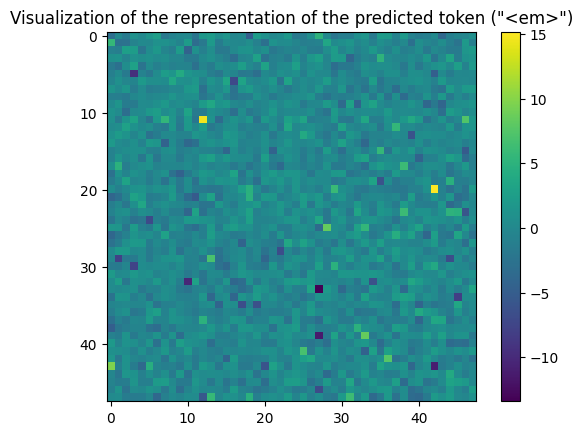

In [ ]:
plt.imshow(m.reshape(48,48));
plt.title("""Visualization of the representation of the predicted token ("<em>")""")
plt.colorbar()

In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['hook_embed'])

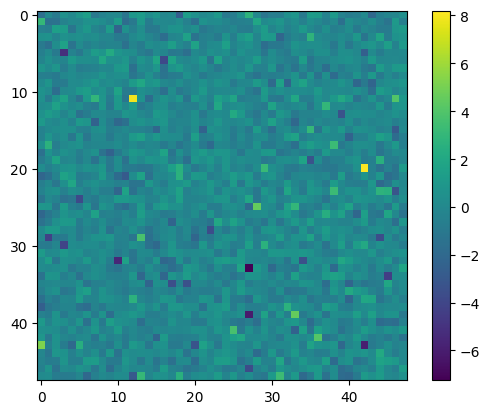

In [ ]:
m=activations_norm_ln_final.detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

In [ ]:
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
# my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

<em> 0.002
<strong> 0.002
<i> 0.002
  0.002
</em> 0.002
<b> 0.002
   0.002
</strong> 0.002
<u> 0.002


 0.002


In [ ]:
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
# my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

<em> 1.0
<strong> 0.0
<i> 0.0
<pad> 0.0
[@BOS@] 0.0
<unk> 0.0
<2mass> 0.0
<mask> 0.0
<eos> 0.0
<bos> 0.0


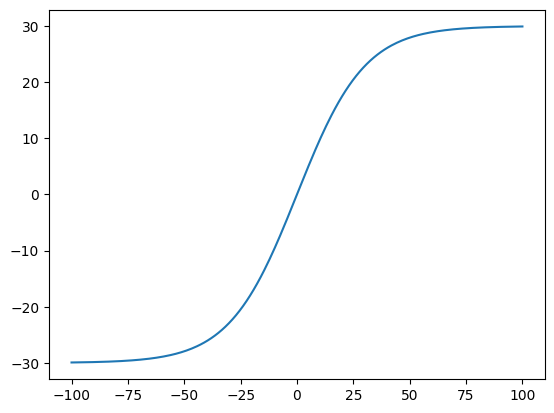

In [ ]:
#Softcapping
xs=t.tensor(np.linspace(-100, 100, 256))
ys=gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(xs / gemma_2_2b.cfg.output_logits_soft_cap)
plt.plot(xs,ys)

## First Attention Block

In [ ]:
t.testing.assert_close(cache['hook_embed']+cache['blocks.0.hook_attn_out'], cache['blocks.0.hook_resid_mid'])

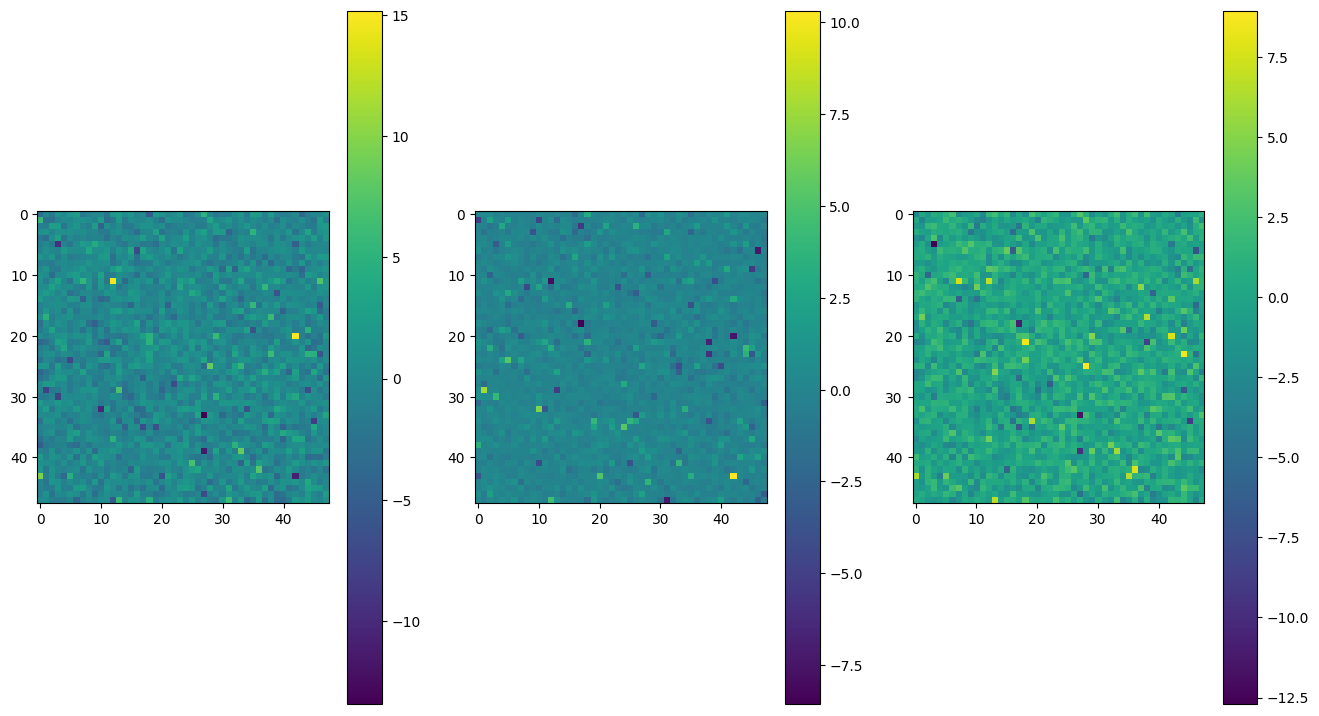

In [ ]:
fig=plt.figure(0, (16,9))
fig.add_subplot(1,3,1)
m=cache['hook_embed'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

fig.add_subplot(1,3,2)
m=cache['blocks.0.hook_attn_out'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

fig.add_subplot(1,3,3)
m=cache['blocks.0.hook_resid_mid'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.0.hook_attn_out'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
# my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

 Anſ 0.0
 Jefus 0.0
 themſelves 0.0
 raiſ 0.0
ſelf 0.0
 iſt 0.0
 ſind 0.0
ſelves 0.0
^(@) 0.0
 doubtnut 0.0


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.0.hook_resid_mid'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
# my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

<em> 0.0181
<i> 0.0181
<strong> 0.0181
</em> 0.0179
<u> 0.0178
<code> 0.0175
</strong> 0.0175
<sup> 0.0174
<b> 0.0172
<sub> 0.0166


## Layer 1 MLP


In [ ]:
t.testing.assert_close(cache['blocks.0.hook_resid_mid']+cache['blocks.0.hook_mlp_out'], cache['blocks.0.hook_resid_post'])

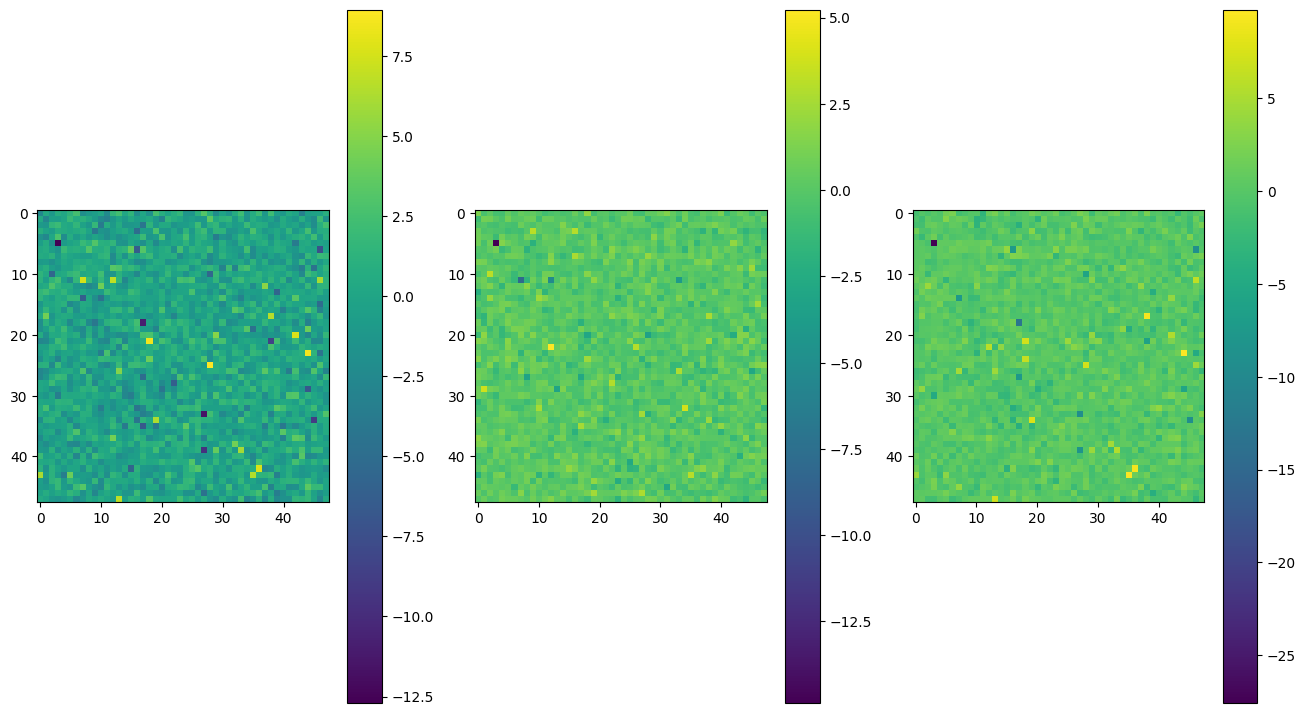

In [ ]:
fig=plt.figure(0, (16,9))
fig.add_subplot(1,3,1)
m=cache['blocks.0.hook_resid_mid'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

fig.add_subplot(1,3,2)
m=cache['blocks.0.hook_mlp_out'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

fig.add_subplot(1,3,3)
m=cache['blocks.0.hook_resid_post'].detach().cpu().numpy()[-1,:]
plt.imshow(m.reshape(48,48)); plt.colorbar()

In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.0.hook_resid_post'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
# my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

<em> 0.0784
<i> 0.078
<strong> 0.0762
</em> 0.0717
<u> 0.0709
<code> 0.0685
<sup> 0.059
<sub> 0.0582
<b> 0.0539
</strong> 0.0531


## Move Through a bunch of Layers

In [ ]:
tokens=gemma_2_2b.to_tokens(prompt)
logits, cache = gemma_2_2b.run_with_cache(tokens, remove_batch_dim=True)
all_res=[]

for layer_id in range(25):
  activations_norm_next_layer=cache['blocks.'+str(layer_id+1)+'.ln1.hook_normalized']
  # activations_norm_ln_final=gemma_2_2b.ln_final(activations)

  my_logits = gemma_2_2b.unembed(activations_norm_next_layer)
  my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
  # my_logits_softcap=my_logits

  probs=my_logits_softcap.softmax(dim=-1)
  token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
  res={}
  for tk, p in zip(token_ids, token_probs):
    res[gemma_2_2b.to_string(tk.item())] = round(p.item(), 4)
  all_res.append(res)

#Final outputs
probs=logits.softmax(dim=-1)
token_probs, token_ids = probs[0,-1, :].topk(10, dim=-1)
res={}
for tk, p in zip(token_ids, token_probs):
  res[gemma_2_2b.to_string(tk.item())] = round(p.item(), 4)
all_res.append(res)
# print(layer_id+1, res)

At the 22th Layer we see that the model will output the answer "love" but not the word "αγάπη" that we expect

In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.22.ln1.hook_normalized'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(15, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

 love 0.3086
love 0.1731
Love 0.1386
LOVE 0.1005
 Love 0.0959
 LOVE 0.0789
 loves 0.0272
 liefde 0.0115
 loving 0.0104
 amour 0.007
 사랑 0.0051
 amor 0.0047
 lovers 0.0037
 Lovers 0.003
 Loves 0.0028


Then at layer 23 something happens, the model tried to switch to another language

## Close Look at 24st Layer (layer 23)

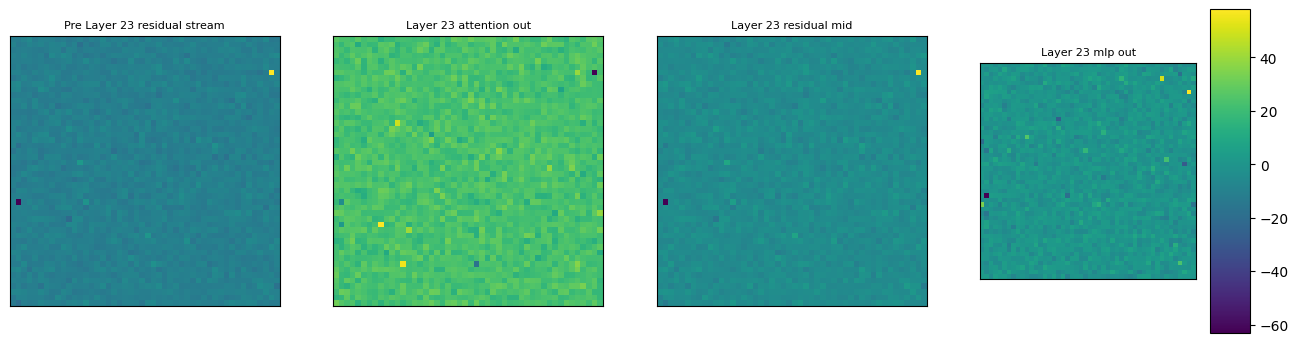

In [ ]:
layer_id=23
subplot_rows=1

residual_stream=cache['blocks.'+str(layer_id)+'.hook_resid_pre'].detach().cpu().numpy()
attn_out=cache['blocks.'+str(layer_id)+'.hook_attn_out'].detach().cpu().numpy()
residual_stream_mid=cache['blocks.'+str(layer_id)+'.hook_resid_mid'].detach().cpu().numpy()
mlp_out=cache['blocks.'+str(layer_id)+'.hook_mlp_out'].detach().cpu().numpy()

fig = plt.figure(0, (16,8))
plt.subplot(subplot_rows,4,1); plt.imshow(residual_stream[-1].reshape(48,48)); plt.title('Pre Layer '+str(layer_id)+' residual stream', fontsize=8); plt.xticks([]); plt.yticks([]);
plt.subplot(subplot_rows,4,2); plt.imshow(attn_out[-1].reshape(48,48)); plt.title('Layer '+str(layer_id)+' attention out', fontsize=8); plt.xticks([]); plt.yticks([]);
plt.subplot(subplot_rows,4,3); plt.imshow(residual_stream_mid[-1].reshape(48,48)); plt.title('Layer '+str(layer_id)+' residual mid', fontsize=8); plt.xticks([]); plt.yticks([]);
plt.subplot(subplot_rows,4,4); plt.imshow(mlp_out[-1].reshape(48,48)); plt.colorbar(aspect=8); plt.title('Layer '+str(layer_id)+' mlp out', fontsize=8); plt.xticks([]); plt.yticks([]);

In [ ]:
resid_post_out=cache['blocks.23.hook_resid_post'].detach().cpu().numpy()

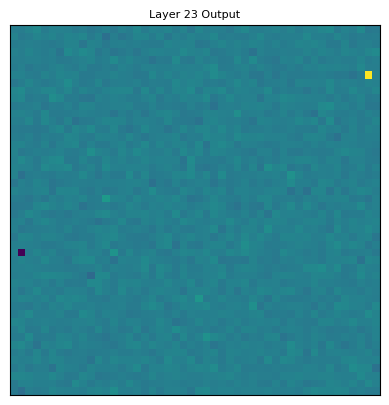

In [ ]:
plt.imshow(residual_stream[-1].reshape(48,48)); plt.title('Layer 23 Output', fontsize=8); plt.xticks([]); plt.yticks([]);

In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.23.hook_resid_post'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(10, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

( 0.4381
<strong> 0.3618
“ 0.1431
<em> 0.0311
I 0.007
< 0.0067
<u> 0.0042
" 0.0038
A 0.0015
<b> 0.0014


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.24.hook_resid_pre'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

( 0.2444
<strong> 0.228
“ 0.1614
<em> 0.088
I 0.0464
< 0.0455
<u> 0.0368
" 0.0351
A 0.023
<b> 0.0222
<i> 0.0129
[ 0.0097
‘ 0.0067
  0.0059
a 0.0039
$ 0.0031
v 0.0023
f 0.0023
1 0.0019

 0.0016


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.24.hook_resid_post'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

I 0.1946
  0.1581
" 0.1396
<strong> 0.1046
“ 0.0803
( 0.0686
<em> 0.034
A 0.0322
f 0.019
a 0.0153
<u> 0.0112
' 0.0095
love 0.0078
E 0.0072
i 0.0067
❤️ 0.0064
   0.0061
e 0.0059
‘ 0.0055
1 0.005


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.25.hook_resid_pre'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

I 0.1946
  0.1581
" 0.1396
<strong> 0.1046
“ 0.0803
( 0.0686
<em> 0.034
A 0.0322
f 0.019
a 0.0153
<u> 0.0112
' 0.0095
love 0.0078
E 0.0072
i 0.0067
❤️ 0.0064
   0.0061
e 0.0059
‘ 0.0055
1 0.005


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.25.hook_resid_post'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

α 0.0925
Α 0.078
A 0.0518
a 0.045
  0.0354
" 0.0344
I 0.0285
E 0.0253
“ 0.0226
Ε 0.015
φ 0.0149
aga 0.014
<strong> 0.0138
Λ 0.0116
alpha 0.0109
phi 0.0101
love 0.0096
i 0.0094
e 0.0093
Φ 0.0087


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.25.hook_attn_out'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

 φ 0.5232
Φ 0.2968
 α 0.0338
 Φ 0.0217
φ 0.0199
Α 0.0177
 ζ 0.0172
 ψ 0.0156
ἀ 0.0048
 ξ 0.0047
 γ 0.0039
 Α 0.0035
Ε 0.0034
ν 0.002
 σ 0.002
 Rho 0.0017
Rho 0.0016
 Λ 0.0016
Σ 0.0016
 π 0.0016


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.25.hook_resid_mid'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

  0.1279
I 0.0841
" 0.0648
α 0.064
<strong> 0.0539
<em> 0.0351
“ 0.0327
Α 0.0325
Greek 0.0311
( 0.0283
A 0.0271
a 0.0172
<u> 0.0156
   0.0118
f 0.0116
love 0.0115
E 0.0107
aga 0.0101
Alpha 0.009
alpha 0.0085


In [ ]:
activations_norm_ln_final=gemma_2_2b.ln_final(cache['blocks.25.hook_resid_post'])
my_logits = gemma_2_2b.unembed(activations_norm_ln_final)
my_logits_softcap = gemma_2_2b.cfg.output_logits_soft_cap * F.tanh(my_logits / gemma_2_2b.cfg.output_logits_soft_cap)
#my_logits_softcap=my_logits

probs=my_logits_softcap.softmax(dim=-1)
token_probs, token_ids = probs[-1, :].topk(20, dim=-1)
for tk, p in zip(token_ids, token_probs):
  print(gemma_2_2b.to_string(tk.item()), round(p.item(), 4))

α 0.0925
Α 0.078
A 0.0518
a 0.045
  0.0354
" 0.0344
I 0.0285
E 0.0253
“ 0.0226
Ε 0.015
φ 0.0149
aga 0.014
<strong> 0.0138
Λ 0.0116
alpha 0.0109
phi 0.0101
love 0.0096
i 0.0094
e 0.0093
Φ 0.0087


## Polysemanticity and Superposition

In [ ]:
def display_dashboard(
    sae_release="gpt2-small-res-jb",
    sae_id="blocks.7.hook_resid_pre",
    latent_idx=0,
    width=1200,
    height=800,
):
    release = get_pretrained_saes_directory()[sae_release]
    neuronpedia_id = release.neuronpedia_id[sae_id]

    url = f"https://neuronpedia.org/{neuronpedia_id}/{latent_idx}?embed=true&embedexplanation=true&embedplots=true&embedtest=true&height=300"

    print(url)
    display(IFrame(url, width=width, height=height))

def steering_hook(
    activations: Float[Tensor, "batch pos d_in"],
    hook: HookPoint,
    sae: SAE,
    latent_idx: int,
    steering_coefficient: float,
) -> Tensor:
    """
    Steers the model by returning a modified activations tensor, with some multiple of the steering vector added to all
    sequence positions.
    """
    return activations + steering_coefficient * sae.W_dec[latent_idx] #Hmm wow how can we visualize this - interesting. Pretty simple in a way.


def generate_with_steering(
    model: HookedSAETransformer,
    sae: SAE,
    prompt: str,
    latent_idx: int,
    steering_coefficient: float = 1.0,
    max_new_tokens: int = 50,
):
    """
    Generates text with steering. A multiple of the steering vector (the decoder weight for this latent) is added to
    the last sequence position before every forward pass.
    """
    _steering_hook = partial(
        steering_hook,
        sae=sae,
        latent_idx=latent_idx,
        steering_coefficient=steering_coefficient,
    )

    with model.hooks(fwd_hooks=[(sae.cfg.hook_name, _steering_hook)]):
        output = model.generate(prompt, max_new_tokens=max_new_tokens, **GENERATE_KWARGS)

    return output

In [ ]:

_, cache = gemma_2_2b.run_with_cache_with_saes(prompt, saes=[gemma_2_2b_sae])

for name, param in cache.items():
    if "hook_sae" in name:
        print(f"{name:<43}: {tuple(param.shape)}")

blocks.23.hook_resid_post.hook_sae_input   : (1, 12, 2304)
blocks.23.hook_resid_post.hook_sae_acts_pre: (1, 12, 16384)
blocks.23.hook_resid_post.hook_sae_acts_post: (1, 12, 16384)
blocks.23.hook_resid_post.hook_sae_recons  : (1, 12, 2304)
blocks.23.hook_resid_post.hook_sae_output  : (1, 12, 2304)


In [ ]:
# Get top activations on final token
_, cache = gemma_2_2b.run_with_cache_with_saes(
    prompt,
    saes=[gemma_2_2b_sae],
    stop_at_layer=gemma_2_2b_sae.cfg.hook_layer + 1,
)
sae_acts_post = cache[f"{gemma_2_2b_sae.cfg.hook_name}.hook_sae_acts_post"][0, -1, :]

We see which features activate the most.

In [ ]:
sae_acts_post.topk(5)

torch.return_types.topk(
values=tensor([86.1060, 77.8061, 72.7618, 57.0600, 50.9984], device='cuda:0'),
indices=tensor([ 8189,  8057,  6504,  1135, 11031], device='cuda:0'))

Looking at the first 5 fatures, the feature with index 8057 appears to be related to Greek language and themes.

In [ ]:
gemma_2_2b_sae.W_dec[8057].shape

torch.Size([2304])

In [ ]:
gemma_2_2b_sae.W_dec[8057].detach().cpu().numpy()

array([ 0.01259843,  0.02166842, -0.00950368, ..., -0.00949681,
        0.00267122, -0.00483954], dtype=float32)

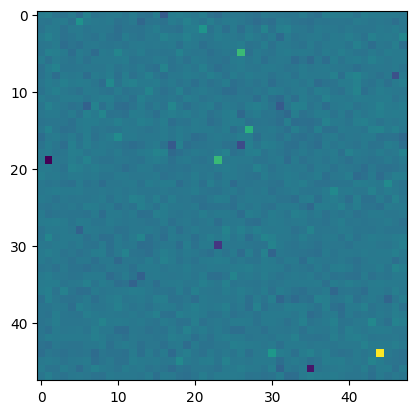

In [ ]:
plt.imshow(gemma_2_2b_sae.W_dec[8057].detach().reshape(48,48).cpu().numpy())

In [ ]:
sae_acts_post.shape

torch.Size([16384])

In [ ]:
for act, ind in zip(*sae_acts_post.topk(3)):
    print(f"Latent {ind} had activation {act:.2f}")
    # display_dashboard(latent_idx=ind)
    display_dashboard(sae_release=gemmascope_sae_release, sae_id=gemmascope_sae_id, latent_idx=ind)

Latent 8189 had activation 86.11
https://neuronpedia.org/gemma-2-2b/23-gemmascope-res-16k/8189?embed=true&embedexplanation=true&embedplots=true&embedtest=true&height=300


Latent 8057 had activation 77.81
https://neuronpedia.org/gemma-2-2b/23-gemmascope-res-16k/8057?embed=true&embedexplanation=true&embedplots=true&embedtest=true&height=300


Latent 6504 had activation 72.76
https://neuronpedia.org/gemma-2-2b/23-gemmascope-res-16k/6504?embed=true&embedexplanation=true&embedplots=true&embedtest=true&height=300


# Steering the model with this feature

In [ ]:
prompt = "My favorite non english word is"
answer = "-"
latent_idx=8057
steering_coefficient = 145 #132.5
GENERATE_KWARGS = dict(temperature=0.5, freq_penalty=2.0, verbose=False)

Base outputs

In [ ]:
gemma_2_2b.generate(prompt, max_new_tokens=50, **GENERATE_KWARGS)

'My favorite non english word is probably "a" in French. I\'m a big fan of the language and I like learning new things, so it was easy for me to learn how to speak French. My favorite English word is "I" because it reminds me of my'

In [ ]:
gemma_2_2b.generate("my favorite letter is ", max_new_tokens=50, **GENERATE_KWARGS)

"my favorite letter is <strong>D</strong>.\n\nMy favorite letter is E because it's the last letter of the alphabet and I like to spell things with that letter.\n\nI like my name because it is a unique name and I am different from others.\n\nThe"

Steering the model

In [ ]:
generate_with_steering(gemma_2_2b, gemma_2_2b_sae, prompt, latent_idx, steering_coefficient=steering_coefficient, max_new_tokens = 40)

'My favorite non english word is the Greek word γιατί, which means “why” or “for”. I love it because it’s such a simple word and yet has so many different uses. For example:\n\n1.'

In [ ]:
generate_with_steering(gemma_2_2b, gemma_2_2b_sae, "my favorite letter is ", latent_idx, steering_coefficient=250)

'my favorite letter is <strong><em>σ</em></strong> because it looks like a capital Σ\n\nMy favorite letter is σ, because it looks like a capital Σ.\n\nI don’t know, I just think it’s pretty.\n\nThe answer: <strong><em>σ'

In [ ]:
generate_with_steering(gemma_2_2b, gemma_2_2b_sae, prompt, latent_idx, steering_coefficient=steering_coefficient)

'My favorite non english word is "ψ" which is the Greek letter.\n\nIt\'s a nice one, but I think it\'s better to use the English version, because it\'s easier to pronounce and more common.\n\nI don\'t have a favourite non'

In [ ]:
generate_with_steering(gemma_2_2b, gemma_2_2b_sae, prompt, latent_idx, steering_coefficient=166)

'My favorite non english word is "κλάς", which means class. It\'s a great word to describe the kind of people you are, and it\'s also used in the name of a school.\n\nI like "κλάς" because it sounds so classy'

In [ ]:
generate_with_steering(gemma_2_2b, gemma_2_2b_sae, "my favorite river in the world is ", latent_idx, steering_coefficient=300)

'my favorite river in the world is <strong><em>river ποταμός</em></strong>, γιατί είναι τόσο όμορφο και αχ γι αυτό το σ και το δ και β γι αυτό το α\n\n( για δυο λόγια η γ ας πμε φ'